# Sentiment Analysis Tool

**Syntecxhub AI Internship · Week 2 · Project 2**

This notebook walks through the full pipeline step by step:

1. Load labelled tweets
2. Explore the data
3. Preprocess text (clean, tokenise)
4. Fix data-quality problems
5. Convert text to numeric features (CountVectorizer and TF-IDF)
6. Train Naive Bayes and Logistic Regression, compare them
7. Evaluate the best model (accuracy, F1, confusion matrix)
8. Inspect what the model learned
9. Two experiments: label leakage and negation handling
10. Predict new text
11. Reaching 90 %+: the same method on 50,000 IMDb reviews
12. Tweets labelled by people: 91 % on airline tweets
13. Neutral text and everyday language: a 3-class model trained on several domains
14. Trustworthy confidence: probability calibration

It uses the same code as the command-line tools (`sentiment/` package, `train.py`, `predict.py`), so results here match the CLI.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

from sentiment.data import load_dataset, load_tweets, load_tweeteval, prepare
from sentiment.preprocess import TextCleaner
from sentiment.model import (ALL_CONFIGS, Config, build_pipeline, calibration_error, cross_validate,
                             evaluate, is_imbalanced, predict, top_features, tuning_grid)
from sentiment import plots

SEED = 42
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
POSITIVE, NEGATIVE = plots.POSITIVE, plots.NEGATIVE
print("Ready")

Ready


## 1. Load the data

The NLTK **twitter_samples** corpus: 5,000 positive and 5,000 negative English tweets from 2015. It downloads automatically the first time (about 16 MB).

In [2]:
df_raw = load_tweets()
print(df_raw.shape)
df_raw.sample(6, random_state=SEED)

(10000, 2)


,text,label
6252,"I love you, how but you? @Taecyeon2pm8 did you feel the same? Emm I think not :(",negative
4684,@mayusushita @dildeewana_ @sonalp2591 @deepti_ahmd @armansushita8 Thanks Guys :),positive
1731,"Your love, O Lord, is better than life. :) &lt;3 https://t.co/KPCeYJqKLM",positive
4742,@yasminyasir96 yeah but it will be better if we use her official Account :) Like The O...,positive
4521,Ok good night I wish troye wasn't ugly and I met him today:)():)!:!; but ok today was ...,positive
6340,"@scottybev I'm not surprised, that sounds hellish! Why would you do such a thing? :(",negative


## 2. Explore the data

label
positive    5000
negative    5000

Words per tweet:
          mean   50%   max
label                     
negative  11.4  10.0  35.0
positive  11.9  11.0  31.0


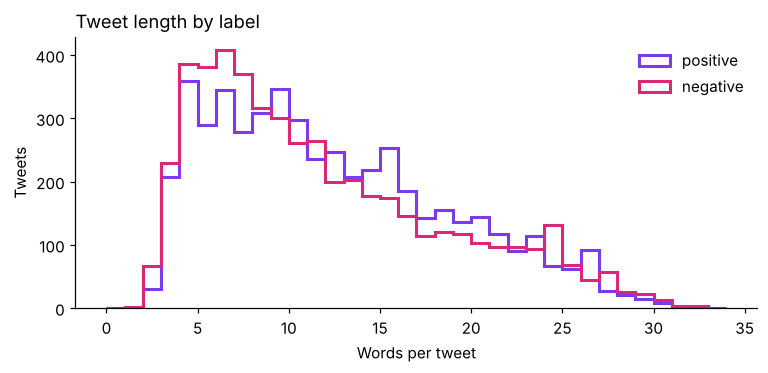

In [3]:
counts = df_raw["label"].value_counts()
print(counts.to_string())

df_raw["n_words"] = df_raw["text"].str.split().str.len()
print("\nWords per tweet:")
print(df_raw.groupby("label")["n_words"].describe()[["mean", "50%", "max"]].round(1))

fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.arange(0, 35, 1)
ax.hist(df_raw.loc[df_raw.label == "positive", "n_words"], bins=bins, histtype="step", linewidth=2, color=POSITIVE, label="positive")
ax.hist(df_raw.loc[df_raw.label == "negative", "n_words"], bins=bins, histtype="step", linewidth=2, color=NEGATIVE, label="negative")
ax.set_xlabel("Words per tweet"); ax.set_ylabel("Tweets"); ax.set_title("Tweet length by label", loc="left")
ax.legend(frameon=False)
plt.show()

### How were these tweets labelled?

The corpus documentation says the tweets were collected by searching for emoticons. Let's check how often `:)` and `:(` appear in each class.

In [4]:
has_smile = df_raw["text"].str.contains(r":-?\)|:D", regex=True)
has_frown = df_raw["text"].str.contains(r":-?\(", regex=True)
pd.DataFrame({
    "contains :) or :D": has_smile.groupby(df_raw.label).mean().map("{:.0%}".format),
    "contains :(": has_frown.groupby(df_raw.label).mean().map("{:.0%}".format),
})

,contains :) or :D,contains :(
label,,
negative,0%,99%
positive,97%,0%


Almost every positive tweet has a smiley and almost every negative tweet has a frown. **The label is written inside the text.** A model that keeps emoticons would simply read the answer back, so the cleaner removes them (experiment in section 9).

## 3. Preprocess text: clean and tokenise

`TextCleaner` (in `sentiment/preprocess.py`) applies these steps:

| Step | Example |
|---|---|
| Remove URLs and @mentions, keep hashtag words | `@bob see #Happy https://x.co` → `see happy` |
| Remove emoticons and emoji | `great :)` → `great` |
| Lowercase, fold accents | `BELİEVE café` → `believe cafe` |
| Expand *n't*, shorten elongated words | `don't`, `soooo` → `do not`, `soo` |
| Tokenise, remove stopwords but **keep negations** | `this is not good` → `not good` |
| Negation marking until punctuation | `not happy, thanks` → `not not_happy thanks` |

In [5]:
cleaner = TextCleaner()
examples = [
    "@Lamb2ja Hey James! How odd :/ Please call our Contact Centre on 02392441234 :) Many thanks!",
    "I don't like this at all :( soooo disappointed http://t.co/xyz",
    "I BELİEVE THAT HE WİLL FOLLOW #Hopeful",
    "not bad, actually pretty fun!",
]
pd.DataFrame({"raw text": examples, "tokens": [cleaner.tokenize(t) for t in examples]})

,raw text,tokens
0,@Lamb2ja Hey James! How odd :/ Please call our Contact Centre on 02392441234 :) Many t...,"[hey, james, odd, contact, centre, thanks]"
1,I don't like this at all :( soooo disappointed http://t.co/xyz,"[not, not_like, soo, disappointed]"
2,I BELİEVE THAT HE WİLL FOLLOW #Hopeful,"[believe, follow, hopeful]"
3,"not bad, actually pretty fun!","[not, not_bad, actually, pretty, fun]"


## 4. Fix data-quality problems

After cleaning, some tweets become empty (they contained only emoticons or mentions), some are near-duplicates (spam like "followed thanks followed"), and some identical texts carry both labels. Duplicates are a problem because copies can end up in both the training and the test set, which makes the test score look better than it is.

In [6]:
cleaned = pd.Series(cleaner.transform(df_raw["text"].tolist()))
print("Most repeated texts after cleaning:")
print(cleaned.value_counts().head(5).to_string())

df, stats = prepare(df_raw.drop(columns="n_words"), cleaner)
print()
print(stats)
print(df["label"].value_counts().to_string())

Most repeated texts after cleaning:
                                                  122
follow follow                                      62
followed thanks followed                           51
thank                                              50
hi bam follow bestfriend loves lot warsaw love     44



{'loaded': 10000, 'empty_after_cleaning': 122, 'conflicting_labels': 250, 'near_duplicates': 860, 'kept': 8768}
label
negative    4525
positive    4243


## 5. Train/test split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"].tolist(), df["label"].tolist(), test_size=0.2, random_state=SEED, stratify=df["label"])
print(f"Train: {len(X_train):,}   Test: {len(X_test):,}")

# Clean once for the step-by-step part below
Xtr_clean = cleaner.transform(X_train)
Xte_clean = cleaner.transform(X_test)

Train: 7,014   Test: 1,754


## 6. Convert text to numeric features

- **CountVectorizer**: each column is a word, each value is how often it occurs.
- **TF-IDF**: the same counts, re-weighted so words that appear in many tweets count less.

`min_df=2` ignores words seen only once (mostly typos and usernames).

In [8]:
count_vec = CountVectorizer(token_pattern=r"\S+", min_df=2)
tfidf_vec = TfidfVectorizer(token_pattern=r"\S+", min_df=2, sublinear_tf=True)
Xtr_count = count_vec.fit_transform(Xtr_clean); Xte_count = count_vec.transform(Xte_clean)
Xtr_tfidf = tfidf_vec.fit_transform(Xtr_clean); Xte_tfidf = tfidf_vec.transform(Xte_clean)

print(f"Vocabulary size: {len(count_vec.vocabulary_):,} words")
print(f"Matrix shape: {Xtr_count.shape}, non-zero values: {Xtr_count.nnz / np.prod(Xtr_count.shape):.3%}")

sample = "thanks so much, I love this song"
row_c = count_vec.transform(cleaner.transform([sample]))
row_t = tfidf_vec.transform(cleaner.transform([sample]))
words = count_vec.get_feature_names_out()
nz = row_c.nonzero()[1]
pd.DataFrame({"word": words[nz], "count": row_c.toarray()[0, nz],
              "tf-idf": row_t.toarray()[0, [tfidf_vec.vocabulary_[w] for w in words[nz]]].round(3)})

Vocabulary size: 3,637 words
Matrix shape: (7014, 3637), non-zero values: 0.119%


,word,count,tf-idf
0,love,1,0.499
1,song,1,0.725
2,thanks,1,0.475


## 7. Train the classifiers

First the four basic combinations, trained directly so each step is visible:

In [9]:
results = []
for vec_name, Xtr, Xte in [("CountVectorizer", Xtr_count, Xte_count), ("TF-IDF", Xtr_tfidf, Xte_tfidf)]:
    for clf_name, clf in [("Naive Bayes", MultinomialNB()),
                          ("Logistic Regression", LogisticRegression(max_iter=2000, random_state=SEED))]:
        clf.fit(Xtr, y_train)
        pred = clf.predict(Xte)
        results.append({"features": vec_name, "classifier": clf_name,
                        "accuracy": accuracy_score(y_test, pred),
                        "macro F1": f1_score(y_test, pred, average="macro")})
pd.DataFrame(results).round(3)

,features,classifier,accuracy,macro F1
0,CountVectorizer,Naive Bayes,0.725,0.723
1,CountVectorizer,Logistic Regression,0.729,0.727
2,TF-IDF,Naive Bayes,0.731,0.730
3,TF-IDF,Logistic Regression,0.733,0.731


### Fair model selection with cross-validation

Picking the model with the best *test* score would quietly tune the model to the test set. Instead, all 8 variants (2 feature types × 2 classifiers × unigrams or uni+bigrams) are compared with **5-fold cross-validation on the training set only**. The test set is used once, at the end.

In [10]:
cv_rows = [cross_validate(cfg, X_train, y_train, folds=5, seed=SEED, n_jobs=-1) for cfg in ALL_CONFIGS]
stage1_best = max(cv_rows, key=lambda r: r["cv_f1_mean"])
print("Stage 1 best:", stage1_best["config"].name)
pd.DataFrame([{"model": r["config"].name, "CV macro F1": r["cv_f1_mean"], "std": r["cv_f1_std"]}
              for r in cv_rows]).sort_values("CV macro F1", ascending=False).round(4).reset_index(drop=True)

Stage 1 best: TF-IDF + Logistic Regression (uni+bigrams)


,model,CV macro F1,std
0,TF-IDF + Logistic Regression (uni+bigrams),0.7305,0.0069
1,CountVectorizer + Naive Bayes (uni+bigrams),0.7299,0.0039
2,CountVectorizer + Logistic Regression (uni+bigrams),0.7289,0.0044
3,TF-IDF + Naive Bayes (uni+bigrams),0.7288,0.0085
4,CountVectorizer + Naive Bayes (unigrams),0.7281,0.0063
5,TF-IDF + Naive Bayes (unigrams),0.7273,0.0079
6,TF-IDF + Logistic Regression (unigrams),0.7270,0.0076
7,CountVectorizer + Logistic Regression (unigrams),0.7256,0.0055


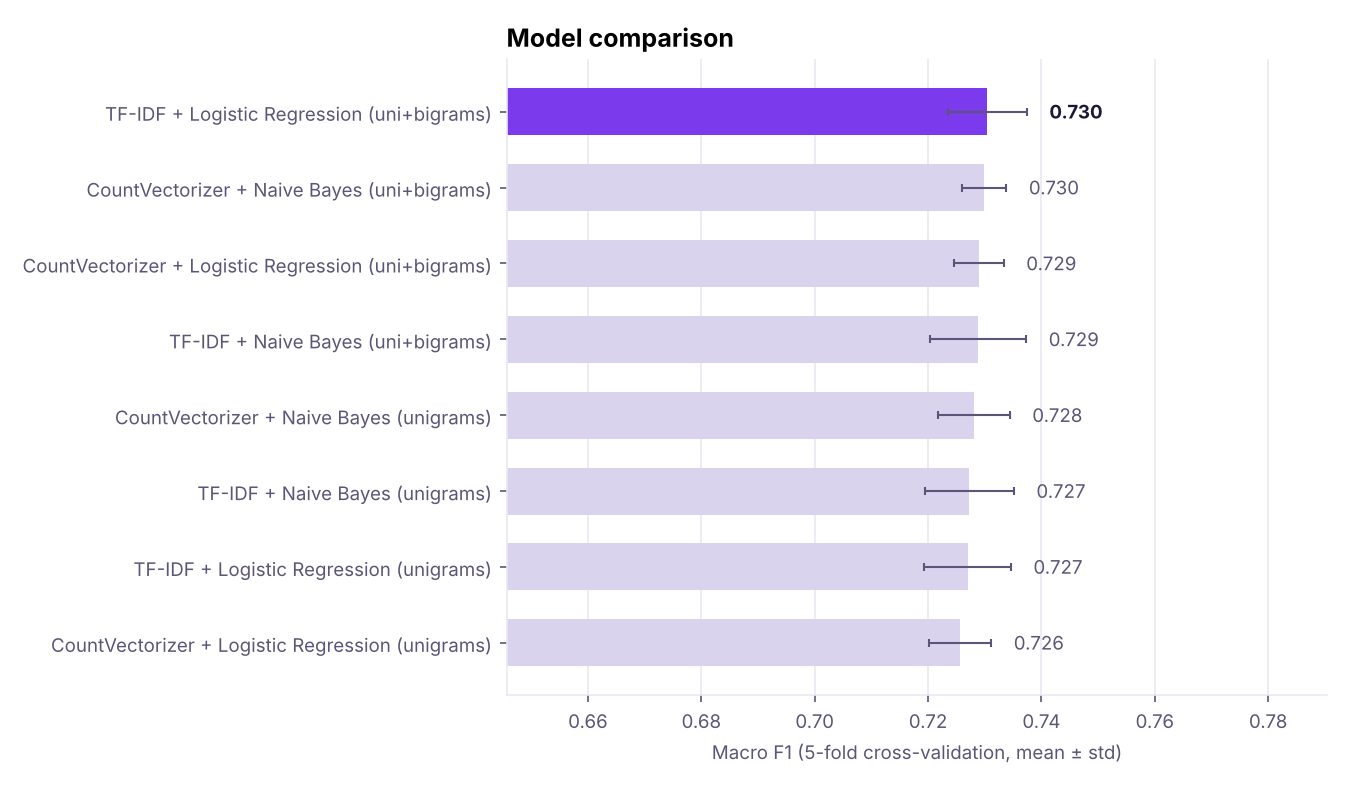

In [11]:
best = stage1_best
plots.model_comparison(cv_rows, best["config"].name, "results/notebook_model_comparison.png")
display(Image("results/notebook_model_comparison.png", width=760))

All eight variants are within about half a point of each other. On short, noisy tweets, the choice of features and classifier matters much less than the quality of the data.

### Stage 2: tuning the best combination

Two settings are tuned with the same cross-validation:
- **Regularisation:** `alpha` for Naive Bayes (lower = less smoothing) or `C` for Logistic Regression (higher = less regularisation)
- **Stopwords:** removed or kept. In short tweets, words like "i'm" or "you" can carry sentiment.

In [12]:
tuned_rows = [cross_validate(cfg, X_train, y_train, folds=5, seed=SEED, n_jobs=-1)
              for cfg in tuning_grid(stage1_best["config"])]
all_rows = cv_rows + tuned_rows
best = max(all_rows, key=lambda r: r["cv_f1_mean"])
print("Best after tuning:", best["config"].name)
pd.DataFrame([{"model": r["config"].name, "CV macro F1": r["cv_f1_mean"], "std": r["cv_f1_std"]}
              for r in [stage1_best] + tuned_rows]).sort_values("CV macro F1", ascending=False).round(4).reset_index(drop=True)

Best after tuning: TF-IDF + Logistic Regression (uni+bigrams), stopwords kept


,model,CV macro F1,std
0,"TF-IDF + Logistic Regression (uni+bigrams), stopwords kept",0.7442,0.0035
1,"TF-IDF + Logistic Regression (uni+bigrams), C=4, stopwords kept",0.7410,0.0031
2,"TF-IDF + Logistic Regression (uni+bigrams), C=10, stopwords kept",0.7365,0.0053
3,TF-IDF + Logistic Regression (uni+bigrams),0.7305,0.0069
4,"TF-IDF + Logistic Regression (uni+bigrams), C=4",0.7242,0.0085
5,"TF-IDF + Logistic Regression (uni+bigrams), C=10",0.7125,0.0056


## 8. Evaluate the best model on the test set

In [13]:
model = build_pipeline(best["config"], seed=SEED).fit(X_train, y_train)
m = evaluate(model, X_test, y_test)

print(best["config"].name)
print(f"Accuracy:          {m['accuracy']:.3f}")
print(f"Precision (macro): {m['precision_macro']:.3f}")
print(f"Recall (macro):    {m['recall_macro']:.3f}")
print(f"F1 (macro):        {m['f1_macro']:.3f}")
print()
print(classification_report(y_test, model.predict(X_test), digits=3))

TF-IDF + Logistic Regression (uni+bigrams), stopwords kept
Accuracy:          0.757
Precision (macro): 0.758
Recall (macro):    0.755
F1 (macro):        0.755

              precision    recall  f1-score   support

    negative      0.744     0.806     0.773       905
    positive      0.773     0.704     0.737       849

    accuracy                          0.757      1754
   macro avg      0.758     0.755     0.755      1754
weighted avg      0.758     0.757     0.756      1754



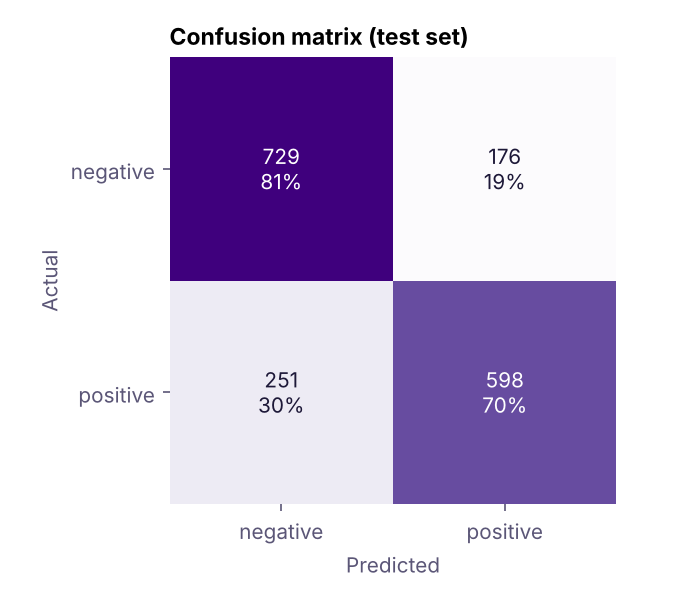

In [14]:
plots.confusion(m["confusion_matrix"], m["labels"], "results/notebook_confusion_matrix.png")
display(Image("results/notebook_confusion_matrix.png", width=380))

### What did the model learn?

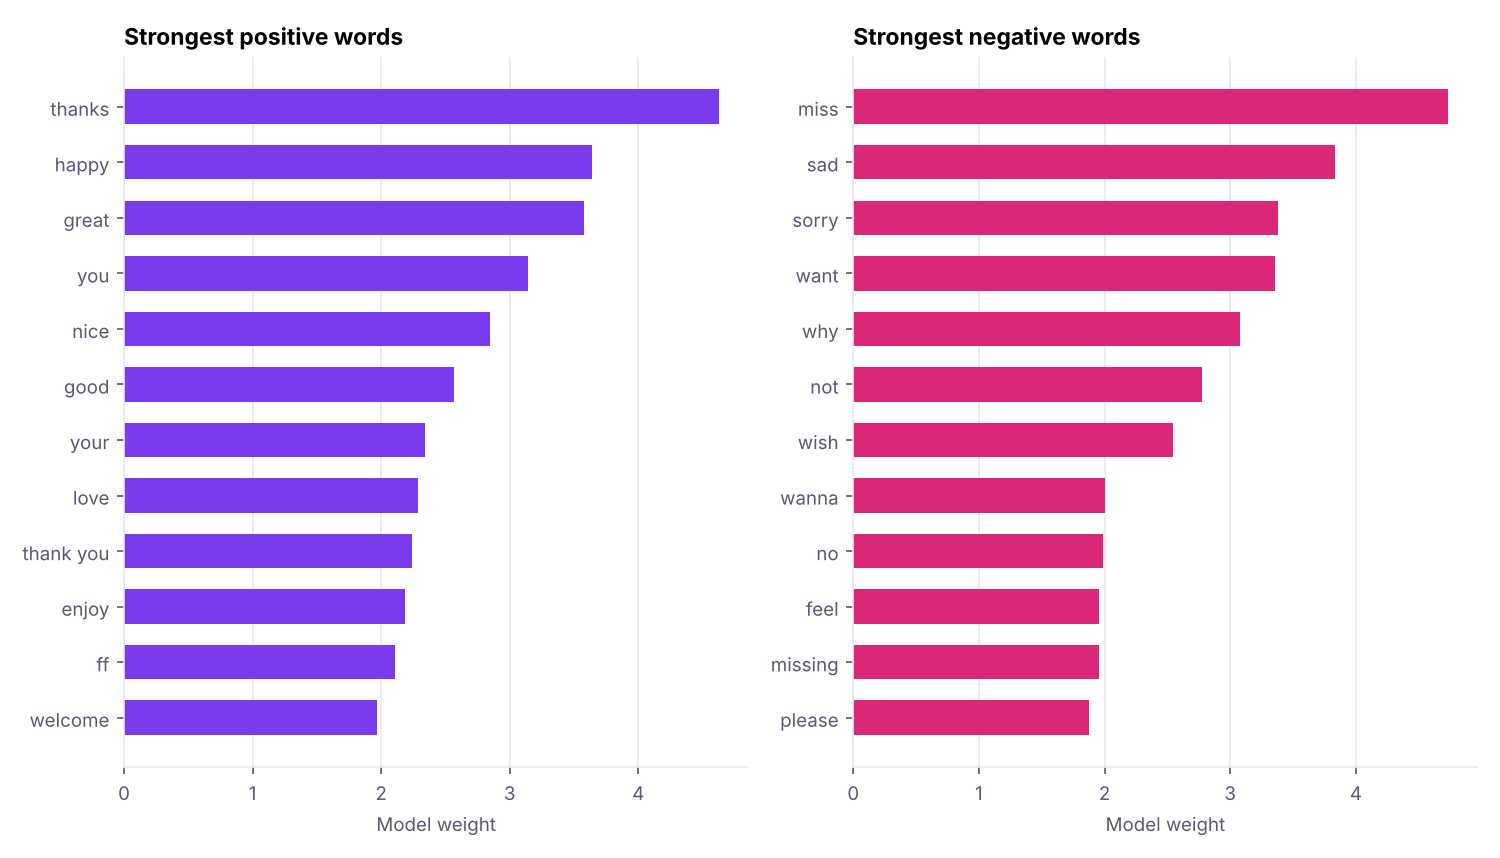

In [15]:
feats = top_features(model, 12)
plots.top_words(feats, "results/notebook_top_words.png")
display(Image("results/notebook_top_words.png", width=820))

Three kinds of signal show up: real sentiment words ("thanks", "happy", "great" against "miss", "sad", "sorry"), everyday words that only carry signal because stopwords are kept ("you", "your", "why"), and artefacts of how the corpus was collected, such as Follow-Friday shout-outs ("ff"), that would not generalise to new data.

## 9. Experiments

### 9a. Label leakage: what if emoticons are kept?

In [16]:
df_emo, _ = prepare(df_raw.drop(columns="n_words"), TextCleaner(remove_emoticons=False))
Xa, Xb, ya, yb = train_test_split(df_emo["text"].tolist(), df_emo["label"].tolist(),
                                  test_size=0.2, random_state=SEED, stratify=df_emo["label"])
leaky = build_pipeline(best["config"], remove_emoticons=False, seed=SEED).fit(Xa, ya)
leak_acc = accuracy_score(yb, leaky.predict(Xb))
print(f"Emoticons removed: {m['accuracy']:.1%} accuracy")
print(f"Emoticons kept:    {leak_acc:.1%} accuracy  <- not real skill, the label is in the text")

Emoticons removed: 75.7% accuracy
Emoticons kept:    99.5% accuracy  <- not real skill, the label is in the text


### 9b. Does negation marking help?

In [17]:
plain = build_pipeline(best["config"], seed=SEED)
plain.set_params(clean__mark_negation=False)
plain.fit(X_train, y_train)

probes = ["not happy with this at all", "this is not good", "not bad at all", "I can't wait"]
rows = []
for t in probes:
    a, b = predict(plain, t), predict(model, t)
    rows.append({"text": t,
                 "without negation marking": f"{a['label']} ({a['confidence']:.0%})",
                 "with negation marking": f"{b['label']} ({b['confidence']:.0%})"})
print(f"Test accuracy without: {accuracy_score(y_test, plain.predict(X_test)):.3f}   "
      f"with: {m['accuracy']:.3f}")
pd.DataFrame(rows)

Test accuracy without: 0.757   with: 0.757


,text,without negation marking,with negation marking
0,not happy with this at all,positive (53%),negative (63%)
1,this is not good,negative (73%),negative (84%)
2,not bad at all,negative (71%),negative (60%)
3,I can't wait,negative (66%),negative (54%)


Overall test accuracy does not change (0.757 either way). The clearest benefit is on negated phrases such as "not happy". It doesn't fix everything: "I can't wait" (positive in meaning) is still read as negative, a limit of bag-of-words models.

## 10. Predict new text

`predict()` returns the label, the confidence, and the words that pushed the decision. Predictions below 65 % confidence are flagged, because the model has no "neutral" class.

In [18]:
def show(text):
    r = predict(model, text)
    flag = "  ⚠ low confidence" if r["low_confidence"] else ""
    why = ", ".join(f"{w} ({s:+.2f})" for w, s in r["explanation"][:4])
    print(f"{r['label'].upper():8s} {r['confidence']:5.0%}  {text}{flag}")
    print(f"{'':15s}because: {why or 'no known words'}")

for t in ["I absolutely love this new phone, the camera is amazing!",
          "Worst customer service ever. I waited two hours and nobody helped.",
          "I'm so tired of this rain",
          "Thanks for the follow, have a great weekend",
          "The meeting is at 3pm in room 204"]:
    show(t)

POSITIVE   75%  I absolutely love this new phone, the camera is amazing!
               because: love (+0.46), amazing (+0.33), camera (+0.23), new (+0.19)
NEGATIVE   65%  Worst customer service ever. I waited two hours and nobody helped.
               because: worst (+0.36), nobody (+0.17), two (-0.06), hours (+0.06)
NEGATIVE   86%  I'm so tired of this rain
               because: tired (+0.54), so (+0.30), i'm (+0.22), so tired (+0.19)
POSITIVE   98%  Thanks for the follow, have a great weekend
               because: thanks (+1.00), great (+0.89), follow (+0.46), thanks for (+0.45)
NEGATIVE   52%  The meeting is at 3pm in room 204  ⚠ low confidence
               because: at (-0.15), is (+0.15), at pm (+0.13), room (+0.13)


Try your own sentence:

In [19]:
show("Type any sentence here and run the cell")

POSITIVE   60%  Type any sentence here and run the cell  ⚠ low confidence
               because: here (+0.40), type (+0.09), the (+0.06), and (-0.03)


In [20]:
# Interactive loop. Set to True to type sentences one by one (leave the box empty to stop).
INTERACTIVE = False
while INTERACTIVE:
    text = input("Text: ").strip()
    if not text:
        break
    show(text)

## 11. Reaching 90 %+: the same method on 50,000 IMDb reviews

The tweets cap out at about 75 % because they are short and their labels are noisy (section 2). With **more and longer text**, the same classical pipeline does much better. The Stanford IMDb dataset has 50,000 labelled reviews (`data/imdb_reviews.csv.gz`).

In [21]:
imdb_raw = load_dataset("imdb")
imdb, imdb_stats = prepare(imdb_raw, TextCleaner())
print(imdb_stats)
print(imdb["label"].value_counts().to_string())
print("Average words per review:", round(imdb["text"].str.split().str.len().mean()))

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    imdb["text"].tolist(), imdb["label"].tolist(), test_size=0.2, random_state=SEED, stratify=imdb["label"])
print(f"Train: {len(Xi_train):,}   Test: {len(Xi_test):,}")

{'loaded': 49582, 'empty_after_cleaning': 0, 'conflicting_labels': 0, 'near_duplicates': 7, 'kept': 49575}
label
positive    24880
negative    24695


Average words per review: 231
Train: 39,660   Test: 9,915


TF-IDF + Logistic Regression with uni+bigrams (the stage-1 winner in `train.py`), tuned exactly like stage 2: `C` ∈ {1, 4, 10}, stopwords removed or kept, chosen by 3-fold cross-validation (3 folds instead of 5 because each fit on 40,000 reviews takes a while):

In [22]:
imdb_base = Config("tfidf", "lr", (1, 2))
imdb_rows = [cross_validate(cfg, Xi_train, yi_train, folds=3, seed=SEED, n_jobs=-1)
             for cfg in [imdb_base] + tuning_grid(imdb_base)]
imdb_best = max(imdb_rows, key=lambda r: r["cv_f1_mean"])
display(pd.DataFrame([{"model": r["config"].name, "CV macro F1": r["cv_f1_mean"]} for r in imdb_rows])
        .sort_values("CV macro F1", ascending=False).round(4).reset_index(drop=True))

imdb_model = build_pipeline(imdb_best["config"], seed=SEED).fit(Xi_train, yi_train)
mi = evaluate(imdb_model, Xi_test, yi_test)
print(imdb_best["config"].name)
print(f"Test accuracy: {mi['accuracy']:.3f}")
print(f"Test F1 (macro): {mi['f1_macro']:.3f}")
print()
print(classification_report(yi_test, imdb_model.predict(Xi_test), digits=3))

,model,CV macro F1
0,"TF-IDF + Logistic Regression (uni+bigrams), C=10, stopwords kept",0.9112
1,"TF-IDF + Logistic Regression (uni+bigrams), C=4, stopwords kept",0.9105
2,"TF-IDF + Logistic Regression (uni+bigrams), C=10",0.9037
3,"TF-IDF + Logistic Regression (uni+bigrams), C=4",0.9028
4,"TF-IDF + Logistic Regression (uni+bigrams), stopwords kept",0.9024
5,TF-IDF + Logistic Regression (uni+bigrams),0.8967


TF-IDF + Logistic Regression (uni+bigrams), C=10, stopwords kept
Test accuracy: 0.919
Test F1 (macro): 0.919



              precision    recall  f1-score   support

    negative      0.926     0.910     0.918      4939
    positive      0.912     0.928     0.920      4976

    accuracy                          0.919      9915
   macro avg      0.919     0.919     0.919      9915
weighted avg      0.919     0.919     0.919      9915



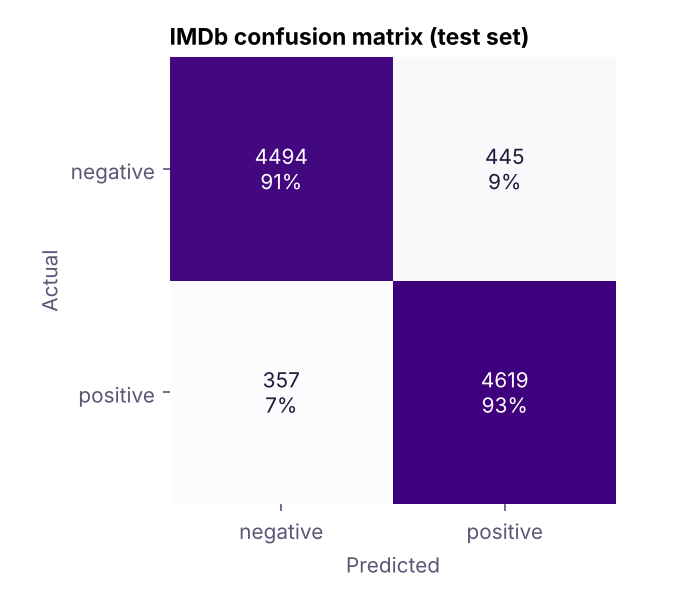

POSITIVE   97%  An absolute masterpiece, the acting and the soundtrack were brilliant.


NEGATIVE  100%  Two hours of my life I will never get back. Dull plot and wooden acting.


NEGATIVE   61%  not bad at all, actually pretty fun


In [23]:
plots.confusion(mi["confusion_matrix"], mi["labels"], "results/notebook_imdb_confusion_matrix.png", title="IMDb confusion matrix (test set)")
display(Image("results/notebook_imdb_confusion_matrix.png", width=380))

for t in ["An absolute masterpiece, the acting and the soundtrack were brilliant.",
          "Two hours of my life I will never get back. Dull plot and wooden acting.",
          "not bad at all, actually pretty fun"]:
    r = predict(imdb_model, t)
    print(f"{r['label'].upper():8s} {r['confidence']:5.0%}  {t}")

## 12. Tweets labelled by people: airline tweets

The NLTK tweets top out at about 76 % because their labels came from emoticons. The **Twitter US Airline Sentiment** dataset has tweets that people read and labelled. Neutral tweets are dropped so the task is positive vs negative, like the rest of the notebook.

Two differences from the NLTK tweets:
- **Emoticons are kept.** Here a 🙏 or `:)` is genuine evidence, not a leaked label.
- **The classes are imbalanced** (81 % negative), so accuracy alone is misleading. The *majority baseline* (always predict "negative"), **balanced accuracy** and **macro-F1** are reported too.

In [24]:
air, air_stats = prepare(load_dataset("airline"), TextCleaner(remove_emoticons=False))
print(air_stats)
print(air["label"].value_counts(normalize=True).round(3).to_string())
Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    air["text"].tolist(), air["label"].tolist(), test_size=0.2, random_state=SEED, stratify=air["label"])

# Same two stages as for the NLTK tweets: 8 combinations, then tune the best one
air_rows = [cross_validate(cfg, Xa_train, ya_train, folds=5, seed=SEED, remove_emoticons=False, n_jobs=-1)
            for cfg in ALL_CONFIGS]
air_s1 = max(air_rows, key=lambda r: r["cv_f1_mean"])
air_rows += [cross_validate(cfg, Xa_train, ya_train, folds=5, seed=SEED, remove_emoticons=False, n_jobs=-1)
             for cfg in tuning_grid(air_s1["config"], is_imbalanced(ya_train))]
air_best = max(air_rows, key=lambda r: r["cv_f1_mean"])
pd.DataFrame([{"model": r["config"].name, "CV macro F1": r["cv_f1_mean"]} for r in air_rows])   .sort_values("CV macro F1", ascending=False).round(4).head(6).reset_index(drop=True)

{'loaded': 11381, 'empty_after_cleaning': 10, 'conflicting_labels': 8, 'near_duplicates': 153, 'kept': 11210}
label
negative    0.807
positive    0.193


,model,CV macro F1
0,"CountVectorizer + Naive Bayes (uni+bigrams), alpha=0.3",0.8706
1,"CountVectorizer + Naive Bayes (uni+bigrams), alpha=0.3, stopwords kept",0.8704
2,"CountVectorizer + Naive Bayes (uni+bigrams), stopwords kept, balanced classes",0.8699
3,"CountVectorizer + Naive Bayes (uni+bigrams), alpha=0.3, stopwords kept, balanced classes",0.8678
4,"CountVectorizer + Naive Bayes (uni+bigrams), alpha=0.1, stopwords kept",0.8670
5,"CountVectorizer + Naive Bayes (uni+bigrams), stopwords kept",0.8654


CountVectorizer + Naive Bayes (uni+bigrams), alpha=0.3
Accuracy:                0.909
Majority-class baseline: 0.807   <- always predicting 'negative'
Balanced accuracy:       0.846
Macro-F1:                0.852

              precision    recall  f1-score   support

    negative      0.939     0.949     0.944      1809
    positive      0.778     0.744     0.760       433

    accuracy                          0.909      2242
   macro avg      0.859     0.846     0.852      2242
weighted avg      0.908     0.909     0.909      2242



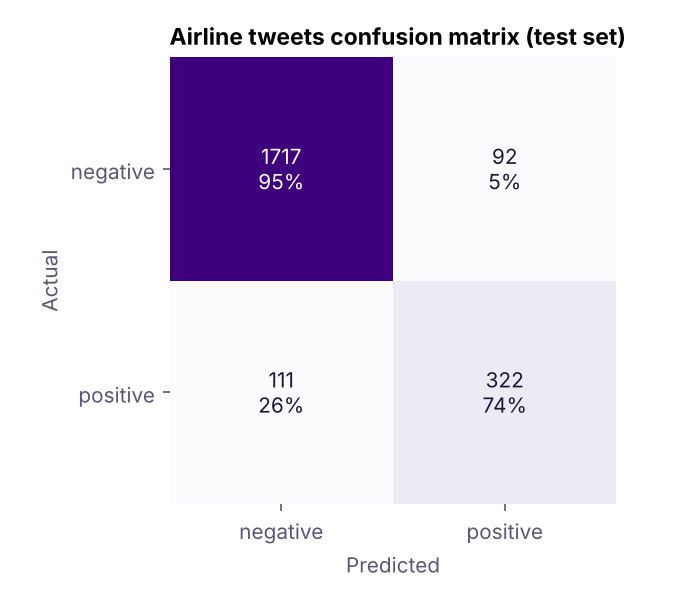

In [25]:
air_model = build_pipeline(air_best["config"], remove_emoticons=False, seed=SEED).fit(Xa_train, ya_train)
ma = evaluate(air_model, Xa_test, ya_test)
print(air_best["config"].name)
print(f"Accuracy:                {ma['accuracy']:.3f}")
print(f"Majority-class baseline: {ma['baseline_accuracy']:.3f}   <- always predicting 'negative'")
print(f"Balanced accuracy:       {ma['balanced_accuracy']:.3f}")
print(f"Macro-F1:                {ma['f1_macro']:.3f}")
print()
print(classification_report(ya_test, air_model.predict(Xa_test), digits=3))
plots.confusion(ma["confusion_matrix"], ma["labels"], "results/notebook_airline_confusion_matrix.png",
                title="Airline tweets confusion matrix (test set)")
display(Image("results/notebook_airline_confusion_matrix.png", width=380))

In [26]:
for t in ["@united thanks for the quick rebooking, great crew :)",
          "Flight delayed 3 hours and no one at the gate can tell us anything",
          "lost my bag again, thanks a lot @AmericanAir",
          "The meeting is at 3pm in room 204"]:
    r = predict(air_model, t)
    print(f"{r['label'].upper():8s} {r['confidence']:5.0%}  {t}")

POSITIVE  100%  @united thanks for the quick rebooking, great crew :)
NEGATIVE  100%  Flight delayed 3 hours and no one at the gate can tell us anything


NEGATIVE   94%  lost my bag again, thanks a lot @AmericanAir
NEGATIVE   96%  The meeting is at 3pm in room 204


The model gets airline complaints and even sarcasm in its own domain right ("thanks a lot" after a lost bag). It also shows the limit of a **binary** model: the neutral meeting sentence must be called positive or negative, and after learning from 81 % complaints it picks negative with high confidence. Section 13 fixes this with a neutral class.

## 13. Neutral text and everyday language: the general 3-class model

The models so far have only two answers, and each was trained on one kind of text. The **general** dataset combines three sources, all labelled by people or star ratings:

- **TweetEval sentiment** (train + validation, 47,615 everyday tweets on many topics, labelled positive / negative / neutral; from SemEval-2017)
- **Airline tweets** with their neutral tweets kept
- a 15,000-review sample of **IMDb**, so longer reviews are covered too

The split is stratified by source *and* label, so each source is represented in the test set.

In [27]:
gen, gen_stats = prepare(load_dataset("general"), TextCleaner(remove_emoticons=False))
print(gen_stats)
display(gen.groupby(["source", "label"]).size().unstack(fill_value=0))
g_train, g_test = train_test_split(gen, test_size=0.2, random_state=SEED,
                                   stratify=gen["source"] + "/" + gen["label"])
print(f"Train: {len(g_train):,}   Test: {len(g_test):,}")

{'loaded': 77014, 'empty_after_cleaning': 38, 'conflicting_labels': 285, 'near_duplicates': 299, 'kept': 76392}


label,negative,neutral,positive
source,,,
airline,9028,2850,2147
imdb,7474,0,7526
tweeteval,7376,21403,18588


Train: 61,113   Test: 15,279


Comparing all 13 settings with cross-validation on 61,000 texts takes a while, so `train.py --dataset general` does it (results in `results/general/metrics.json`). The notebook reuses the winner (and train.py's calibration decision, see section 14) and evaluates it on the test set, per source, and on TweetEval's **official test set** of 12,284 tweets, which was never used for training or model selection.

In [28]:
import json
gm = json.load(open("results/general/metrics.json"))
row = next(c for c in gm["comparison"] if c["model"] == gm["config"])
g_cfg = Config(row["vectorizer"], row["classifier"], tuple(row["ngram"]), row["strength"],
               row["keep_stopwords"], row.get("balanced", False))
gen_model = build_pipeline(g_cfg, remove_emoticons=False, seed=SEED, calibrate=3 if gm["calibrated"] else 0)
gen_model.fit(g_train["text"].tolist(), g_train["label"].tolist())
mg = evaluate(gen_model, g_test["text"].tolist(), g_test["label"].tolist())
print(g_cfg.name)
print(f"Accuracy {mg['accuracy']:.3f}   macro-F1 {mg['f1_macro']:.3f}   baseline {mg['baseline_accuracy']:.3f}")

rows = []
for src, part in g_test.groupby("source"):
    pred = gen_model.predict(part["text"].tolist())
    labels = sorted(part["label"].unique())
    rows.append({"source": src, "texts": len(part), "accuracy": accuracy_score(part["label"], pred),
                 "macro-F1": f1_score(part["label"], pred, labels=labels, average="macro")})
bench = load_tweeteval(("test",))
from sklearn.metrics import recall_score
bp = gen_model.predict(bench["text"].tolist())
rows.append({"source": "TweetEval official test", "texts": len(bench), "accuracy": accuracy_score(bench["label"], bp),
             "macro-F1": f1_score(bench["label"], bp, average="macro")})
print(f"TweetEval official metric (macro-recall): {recall_score(bench['label'], bp, average='macro'):.3f}")
pd.DataFrame(rows).round(3)

TF-IDF + Logistic Regression (unigrams), stopwords kept
Accuracy 0.724   macro-F1 0.725   baseline 0.370


TweetEval official metric (macro-recall): 0.586


,source,texts,accuracy,macro-F1
0,airline,2805,0.796,0.720
1,imdb,3000,0.865,0.865
2,tweeteval,9474,0.658,0.620
3,TweetEval official test,12284,0.608,0.594


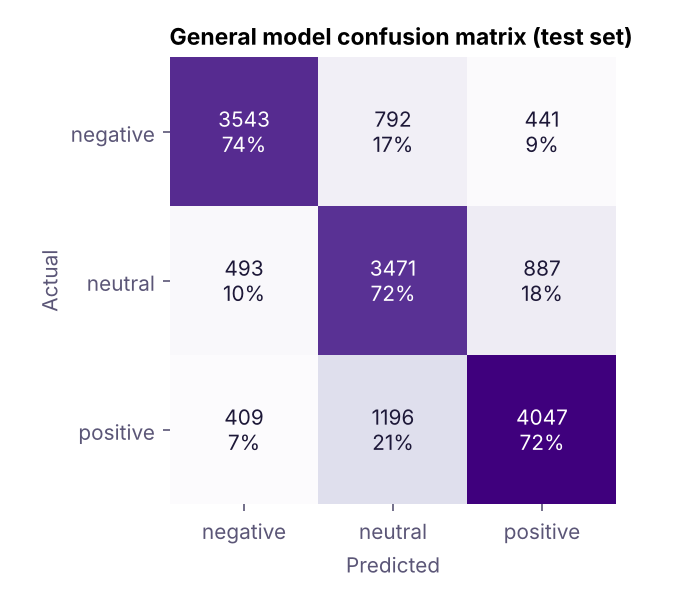

In [29]:
plots.confusion(mg["confusion_matrix"], mg["labels"], "results/notebook_general_confusion_matrix.png",
                title="General model confusion matrix (test set)")
display(Image("results/notebook_general_confusion_matrix.png", width=420))

Now the sentences that the earlier models got wrong:

In [30]:
probes = ["The meeting is at 3pm in room 204", "Is there wifi on the plane?", "The package arrives on Tuesday",
          "I'm watching the game tonight", "lost my bag again, thanks a lot @AmericanAir",
          "The battery died after two days, waste of money", "Works perfectly, very happy with it",
          "Two hours of my life I will never get back.", "great, another Monday"]
fmt = lambda r: f"{r['label']} {r['confidence']:.0%}"
pd.DataFrame([{"text": t, "airline (binary)": fmt(predict(air_model, t)), "IMDb (binary)": fmt(predict(imdb_model, t)),
               "general (3 classes)": fmt(predict(gen_model, t))} for t in probes])

,text,airline (binary),IMDb (binary),general (3 classes)
0,The meeting is at 3pm in room 204,negative 96%,positive 53%,neutral 59%
1,Is there wifi on the plane?,negative 87%,negative 63%,negative 71%
2,The package arrives on Tuesday,negative 98%,positive 59%,neutral 79%
3,I'm watching the game tonight,positive 68%,negative 68%,positive 49%
4,"lost my bag again, thanks a lot @AmericanAir",negative 94%,positive 89%,negative 79%
5,"The battery died after two days, waste of money",negative 100%,negative 100%,negative 92%
6,"Works perfectly, very happy with it",positive 76%,positive 98%,positive 100%
7,Two hours of my life I will never get back.,negative 98%,negative 95%,negative 74%
8,"great, another Monday",positive 75%,positive 88%,positive 99%


The general model is the only one that can answer **neutral**, and it does so for most factual sentences (not all: "wifi" mostly appears in airline complaints). It still gets clear complaints and praise right, including product reviews it never saw. Two things to keep in mind:

- **Accuracy is lower than the binary models** because three classes on everyday tweets is a harder task: the line between neutral and mildly positive is fuzzy even for the people who labelled TweetEval. Fine-tuned transformers reach only about 73 % macro-recall on the official TweetEval test set.
- **Sarcasm** ("great, another Monday") is still missed: a bag-of-words model sees "great" and has no notion of tone.

## 14. Trustworthy confidence: probability calibration

A model's confidence should mean something: of all predictions made with 90 % confidence, about 90 % should be right. Naive Bayes in particular is **over-confident**, because it treats every word as independent evidence. **Calibration** fixes this without changing the model: `CalibratedClassifierCV` with the sigmoid method fits a small correction on out-of-fold predictions. Calibration is not free, and a model that is already well calibrated (Logistic Regression often is) can get slightly worse, so `train.py` keeps it only if it lowers the cross-validated **log loss** on the training set.

The *expected calibration error* (ECE) is the average gap between confidence and actual accuracy (0 = perfect).

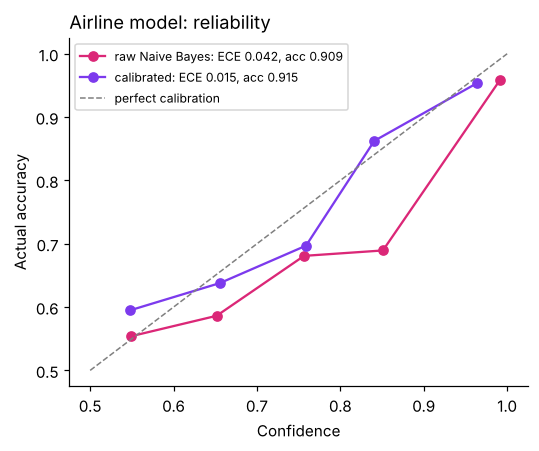

lost my bag again, thanks a lot @AmericanAir   raw negative 94%   calibrated negative 96%
Is there wifi on the plane?                    raw negative 87%   calibrated negative 94%


In [31]:
air_cal = build_pipeline(air_best["config"], remove_emoticons=False, seed=SEED, calibrate=5).fit(Xa_train, ya_train)
fig, ax = plt.subplots(figsize=(5, 4.2))
for name, mdl, color in [("raw Naive Bayes", air_model, NEGATIVE), ("calibrated", air_cal, POSITIVE)]:
    proba = mdl.predict_proba(Xa_test)
    conf = proba.max(axis=1)
    correct = np.asarray(mdl.classes_)[proba.argmax(axis=1)] == np.asarray(ya_test)
    bins = np.linspace(0.5, 1, 6)
    idx = np.clip(np.digitize(conf, bins) - 1, 0, 4)
    xs = [conf[idx == b].mean() for b in range(5) if (idx == b).any()]
    ys = [correct[idx == b].mean() for b in range(5) if (idx == b).any()]
    me = evaluate(mdl, Xa_test, ya_test)
    ax.plot(xs, ys, "o-", color=color, label=f"{name}: ECE {me['calibration_error']:.3f}, acc {me['accuracy']:.3f}")
ax.plot([0.5, 1], [0.5, 1], "--", color="grey", lw=1, label="perfect calibration")
ax.set_xlabel("Confidence"); ax.set_ylabel("Actual accuracy"); ax.set_title("Airline model: reliability", loc="left")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

for t in ["lost my bag again, thanks a lot @AmericanAir", "Is there wifi on the plane?"]:
    print(f"{t:46s} raw {fmt(predict(air_model, t)):14s} calibrated {fmt(predict(air_cal, t))}")

After calibration the curve sits close to the diagonal and accuracy is essentially unchanged.

**The CLI models** are trained by `train.py`, which runs the full model selection and calibration for each dataset; this notebook does not overwrite them.

## Summary

| | NLTK tweets | Airline tweets | IMDb reviews | General (3 classes) |
|---|---|---|---|---|
| Labelled by | emoticons | people | star ratings | people / star ratings |
| Texts after cleaning | 8,768 | 11,210 | 49,575 | 76,392 |
| Best model (chosen by CV) | TF-IDF + Logistic Regression, uni+bigrams, stopwords kept | Count + Naive Bayes, uni+bigrams, alpha=0.3 | TF-IDF + Logistic Regression, uni+bigrams, C=10, stopwords kept | TF-IDF + Logistic Regression, unigrams, stopwords kept |
| **Test accuracy** | **75.7 %** | **90.9 %** | **91.9 %** | **72.4 %** |
| Majority baseline | 51.6 % | 80.7 % | 50.2 % | 37.0 % |
| **Macro-F1** | **0.755** | **0.852** | **0.919** | **0.725** |

(The airline model here keeps raw probabilities; `train.py` calibrates it, which gives 91.5 % on the same test set.)

**Key findings**

- **Label quality matters more than the model.** Short tweets reach about 76 % with emoticon-based labels and about 91 % with labels made by people.
- **Read accuracy against the baseline.** On the airline tweets, always guessing "negative" already gives 80.7 %; macro-F1 (0.852) shows the real skill.
- **Tuning helps:** keeping stopwords raised the tweet model's CV macro-F1 from 0.731 to 0.744; on IMDb a higher `C` plus kept stopwords lifted test accuracy from 90.4 % to 91.9 %.
- **Label leakage:** keeping emoticons in the NLTK tweets gives 99.5 %, which is not real skill.
- **Negation marking** fixes phrases such as "not happy" but does not change overall tweet accuracy.
- **A neutral class needs neutral training data.** The 3-class general model answers *neutral* for factual sentences that every binary model forced into positive or negative. Its accuracy is lower because three classes on everyday tweets is a harder task.
- **Calibration** makes Naive Bayes confidences trustworthy without changing its accuracy much.
- **Still hard for bag-of-words models:** sarcasm ("great, another Monday") and double negatives ("not bad at all").